<a href="https://colab.research.google.com/github/EagleEyes2008/Python/blob/main/Assignment_5_Exploratory_Data_Analysis_with_Pandas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Titanic Dataset Exploratory Data Analysis

# Task 1: Load the Titanic dataset
# TODO: Load the Titanic dataset from the following URL
#Import necessary Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load from local file (if uploaded to Colab) or from the provided URL
# df = pd.read_csv("Titanic-Dataset.csv")
url = "https://web.stanford.edu/class/archive/cs/cs109/cs109.1166/stuff/titanic.csv"
df = pd.read_csv(url)

In [17]:
#Task 2 - Inspect the data
# TODO: Display the First 5 and last 5 rows of the dataset
print("--- First 5 Rows ---")
display(df.head())

print("\n--- Last 5 Rows ---")
display(df.tail())

print("\n--- Data Types ---")
print(df.dtypes)

print("\n--- Summary Statistics ---")
display(df.describe())

--- First 5 Rows ---


,Survived,Pclass,Name,Sex,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare,PclassCategory,Family
0,0,3,Mr. Owen Harris Braund,male,22.0,1,0,7.2500,3rd Class,1
1,1,1,Mrs. John Bradley (Florence Briggs Thayer) Cum...,female,38.0,1,0,71.2833,1st Class,1
2,1,3,Miss. Laina Heikkinen,female,26.0,0,0,7.9250,3rd Class,0
3,1,1,Mrs. Jacques Heath (Lily May Peel) Futrelle,female,35.0,1,0,53.1000,1st Class,1
4,0,3,Mr. William Henry Allen,male,35.0,0,0,8.0500,3rd Class,0



--- Last 5 Rows ---


,Survived,Pclass,Name,Sex,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare,PclassCategory,Family
882,0,2,Rev. Juozas Montvila,male,27.0,0,0,13.00,2nd Class,0
883,1,1,Miss. Margaret Edith Graham,female,19.0,0,0,30.00,1st Class,0
884,0,3,Miss. Catherine Helen Johnston,female,7.0,1,2,23.45,3rd Class,3
885,1,1,Mr. Karl Howell Behr,male,26.0,0,0,30.00,1st Class,0
886,0,3,Mr. Patrick Dooley,male,32.0,0,0,7.75,3rd Class,0



--- Data Types ---
Survived                     int64
Pclass                       int64
Name                        object
Sex                         object
Age                        float64
Siblings/Spouses Aboard      int64
Parents/Children Aboard      int64
Fare                       float64
PclassCategory              object
Family                       int64
dtype: object

--- Summary Statistics ---


,Survived,Pclass,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare,Family
count,887.000000,887.000000,887.000000,887.000000,887.000000,887.00000,887.000000
mean,0.385569,2.305524,29.471443,0.525366,0.383315,32.30542,0.908681
std,0.487004,0.836662,14.121908,1.104669,0.807466,49.78204,1.615949
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.00000,0.000000
25%,0.000000,2.000000,20.250000,0.000000,0.000000,7.92500,0.000000
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.45420,0.000000
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.13750,1.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.32920,10.000000


In [4]:
#Task 3 - Clean and preprocess the data
pclass_map = {1: "1st Class", 2: "2nd Class", 3: "3rd Class"}
df["PclassCategory"] = df["Pclass"].map(pclass_map)

# Impute missing Age values with the mean age (~29.70)
df["Age"] = df["Age"].fillna(df["Age"].mean())

# Create Family feature combining siblings/spouses and parents/children aboard
df["Family"] = df["Siblings/Spouses Aboard"] + df["Parents/Children Aboard"]

print("Missing values after Age imputation:\n", df[["Age", "PclassCategory", "Family"]].isnull().sum())

Missing values after Age imputation:
 Age               0
PclassCategory    0
Family            0
dtype: int64


In [6]:
#Task 4 - Identify specific data points
max_fare = df["Fare"].max()
highest_fare_passengers = df[df["Fare"] == max_fare]
print(f"Highest Fare ({max_fare}):")
display(highest_fare_passengers[["Name", "PclassCategory", "Sex", "Age", "Fare", "Survived"]])

max_family = df["Family"].max()
largest_family_passengers = df[df["Family"] == max_family]
print(f"\nLargest Family Size ({max_family}):")
display(largest_family_passengers[["Name", "PclassCategory", "Sex", "Age", "Family", "Survived"]])

Highest Fare (512.3292):


,Name,PclassCategory,Sex,Age,Fare,Survived
257,Miss. Anna Ward,1st Class,female,35.0,512.3292,1
676,Mr. Thomas Drake Martinez Cardeza,1st Class,male,36.0,512.3292,1
733,Mr. Gustave J Lesurer,1st Class,male,35.0,512.3292,1



Largest Family Size (10):


,Name,PclassCategory,Sex,Age,Family,Survived
158,Master. Thomas Henry Sage,3rd Class,male,5.0,10,0
179,Miss. Constance Gladys Sage,3rd Class,female,8.0,10,0
200,Mr. Frederick Sage,3rd Class,male,17.0,10,0
322,Mr. George John Jr Sage,3rd Class,male,20.0,10,0
788,Miss. Stella Anna Sage,3rd Class,female,21.0,10,0
842,Mr. Douglas Bullen Sage,3rd Class,male,18.0,10,0
859,Miss. Dorothy Edith Sage,3rd Class,female,14.0,10,0



**Highest Fare (512.3292):** 3 passengers—Ward, Miss. Anna, Cardeza, Mr. Thomas Drake Martinez, and Lesurer, Mr. Gustave J—all in 1st Class, all survived.

**Largest Family Size (10):** 7 members of the Sage family (SibSp = 8, Parch = 2) in 3rd Class, none of whom survived in this dataset.



In [7]:
#Task 5 - Demonstrate Pandas Series and DataFrame functionalities
names_series = df["Name"]
print("Series preview:\n", names_series.head())

names_ages_df = df[["Name", "Age"]]
print("\nName & Age DataFrame preview:\n", names_ages_df.head())

older_passengers = df[df["Age"] > 50]
print(f"\nPassengers older than 50 (count = {len(older_passengers)}):")
display(older_passengers[["Name", "Age", "PclassCategory", "Survived"]].head(10))

Series preview:
 0                               Mr. Owen Harris Braund
1    Mrs. John Bradley (Florence Briggs Thayer) Cum...
2                                Miss. Laina Heikkinen
3          Mrs. Jacques Heath (Lily May Peel) Futrelle
4                              Mr. William Henry Allen
Name: Name, dtype: object

Name & Age DataFrame preview:
                                                 Name   Age
0                             Mr. Owen Harris Braund  22.0
1  Mrs. John Bradley (Florence Briggs Thayer) Cum...  38.0
2                              Miss. Laina Heikkinen  26.0
3        Mrs. Jacques Heath (Lily May Peel) Futrelle  35.0
4                            Mr. William Henry Allen  35.0

Passengers older than 50 (count = 72):


,Name,Age,PclassCategory,Survived
6,Mr. Timothy J McCarthy,54.0,1st Class,0
11,Miss. Elizabeth Bonnell,58.0,1st Class,1
15,Mrs. (Mary D Kingcome) Hewlett,55.0,2nd Class,1
33,Mr. Edward H Wheadon,66.0,2nd Class,0
53,Mr. Engelhart Cornelius Ostby,65.0,1st Class,0
63,Mr. Albert A Stewart,64.0,1st Class,0
93,Mr. Daniel Coxon,59.0,3rd Class,0
95,Mr. George B Goldschmidt,71.0,1st Class,0
115,Mr. Patrick Connors,70.5,3rd Class,0
123,Mr. Percival Wayland White,54.0,1st Class,0


In [8]:
#Task 6 - Multi-indexing
multi_index_df = df.groupby(["Sex", "Pclass"])["Survived"].mean().unstack()
print("Survival Rate by Sex (rows) and Pclass (columns):")
display(multi_index_df)

Survival Rate by Sex (rows) and Pclass (columns):


Pclass,1,2,3
Sex,,,
female,0.968085,0.921053,0.500000
male,0.368852,0.157407,0.137026


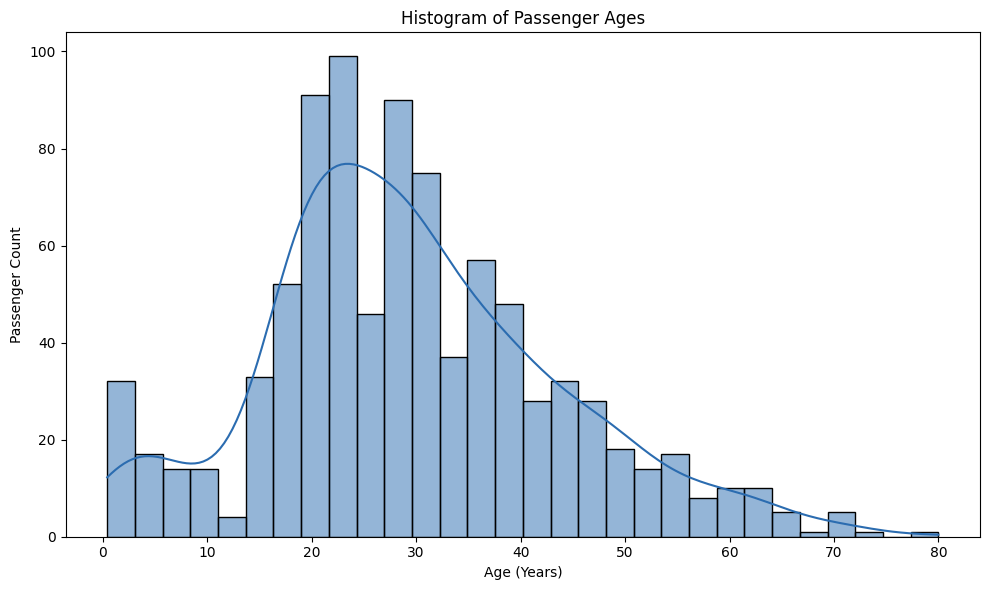

In [9]:
# Task 7a - Histogram of passenger ages
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x="Age", bins=30, kde=True, color="#2b6cb0")
plt.title("Histogram of Passenger Ages")
plt.xlabel("Age (Years)")
plt.ylabel("Passenger Count")
plt.tight_layout()
plt.show()

/tmp/ipykernel_689/1507535526.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="PclassCategory", y="Survived", order=["1st Class", "2nd Class", "3rd Class"], palette="viridis")


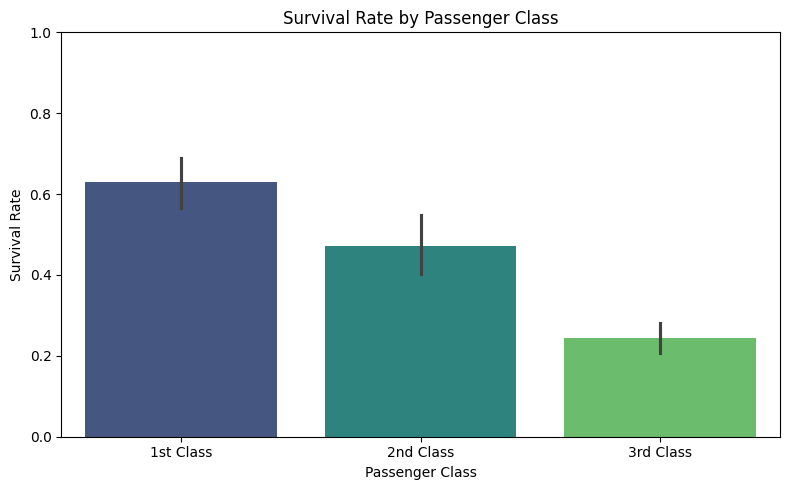

In [10]:
#Task 7b - Bar plot of survival rates by passenger class
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="PclassCategory", y="Survived", order=["1st Class", "2nd Class", "3rd Class"], palette="viridis")
plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

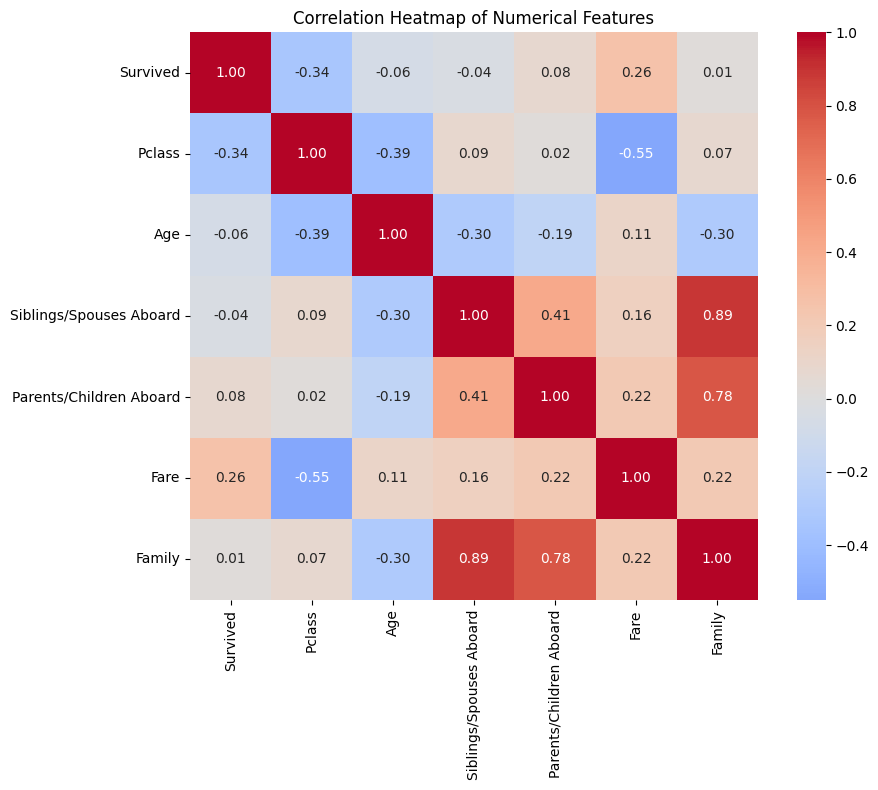

In [11]:
#Task 7c - Heatmap of correlations between numerical features
plt.figure(figsize=(10, 8))
numeric_cols = df.select_dtypes(include=[np.number])
corr_matrix = numeric_cols.corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

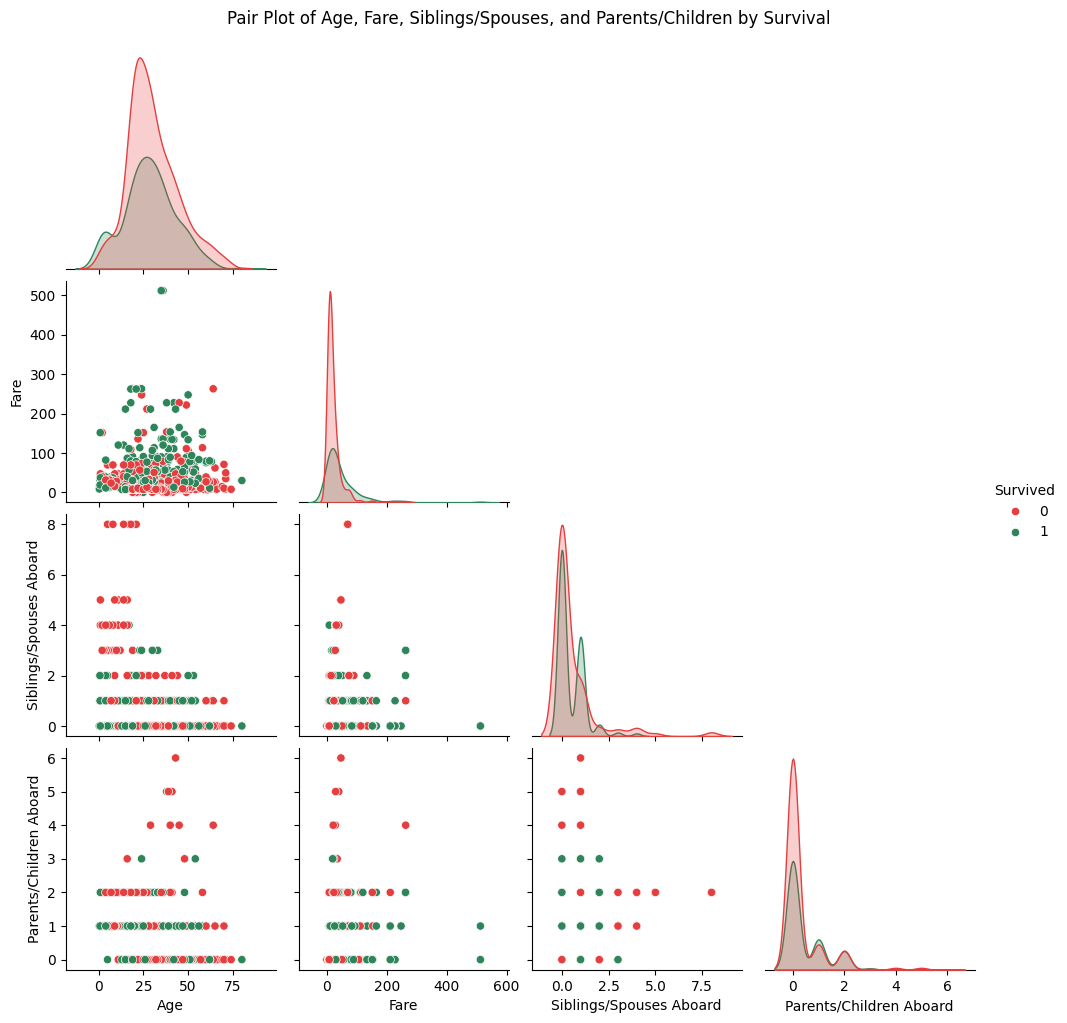

In [13]:
#Task 7d - Pair plot of selected features
pair_features = ["Age", "Fare", "Siblings/Spouses Aboard", "Parents/Children Aboard", "Survived"]
g = sns.pairplot(df[pair_features], hue="Survived", palette={0: "#e53e3e", 1: "#2f855a"}, corner=True)
g.fig.suptitle("Pair Plot of Age, Fare, Siblings/Spouses, and Parents/Children by Survival", y=1.02)
plt.show()

In [14]:
#Task 8 - Analyze survival rates by sex and passenger class
survival_by_sex = df.groupby("Sex")["Survived"].mean()
survival_by_class = df.groupby("PclassCategory")["Survived"].mean().reindex(["1st Class", "2nd Class", "3rd Class"])

print("Survival Rate by Sex:")
print(survival_by_sex)
print("\nSurvival Rate by Passenger Class:")
print(survival_by_class)

Survival Rate by Sex:
Sex
female    0.742038
male      0.190227
Name: Survived, dtype: float64

Survival Rate by Passenger Class:
PclassCategory
1st Class    0.629630
2nd Class    0.472826
3rd Class    0.244353
Name: Survived, dtype: float64


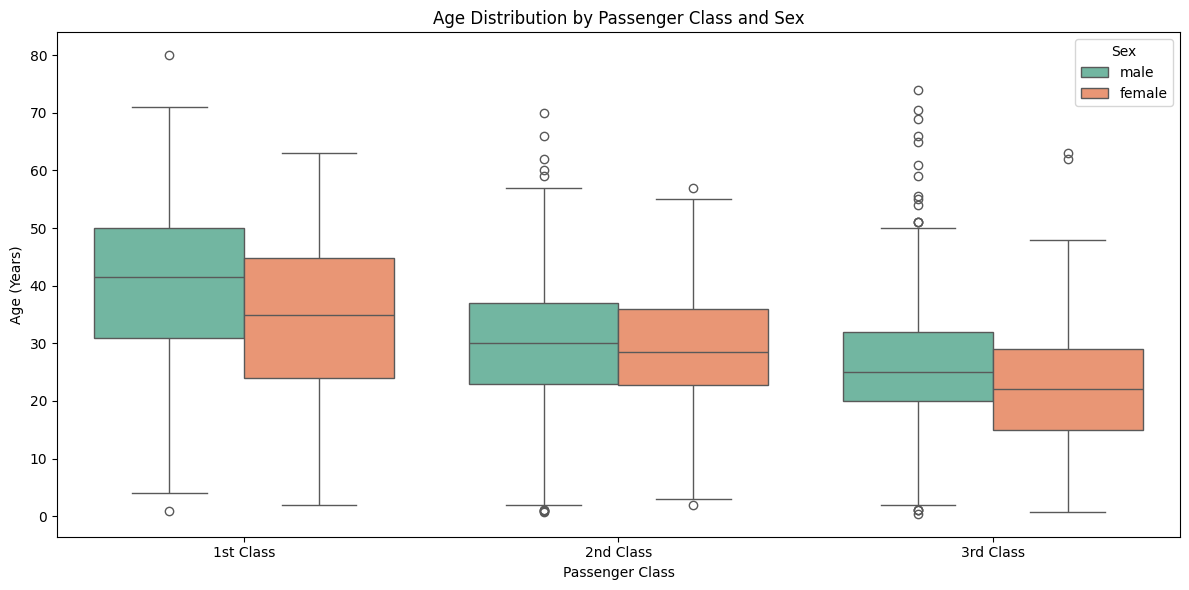

In [15]:
#Task 9 - Analyze age distribution using a box plot
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df,
    x="PclassCategory",
    y="Age",
    hue="Sex",
    order=["1st Class", "2nd Class", "3rd Class"],
    palette="Set2"
)
plt.title("Age Distribution by Passenger Class and Sex")
plt.xlabel("Passenger Class")
plt.ylabel("Age (Years)")
plt.legend(title="Sex")
plt.tight_layout()
plt.show()

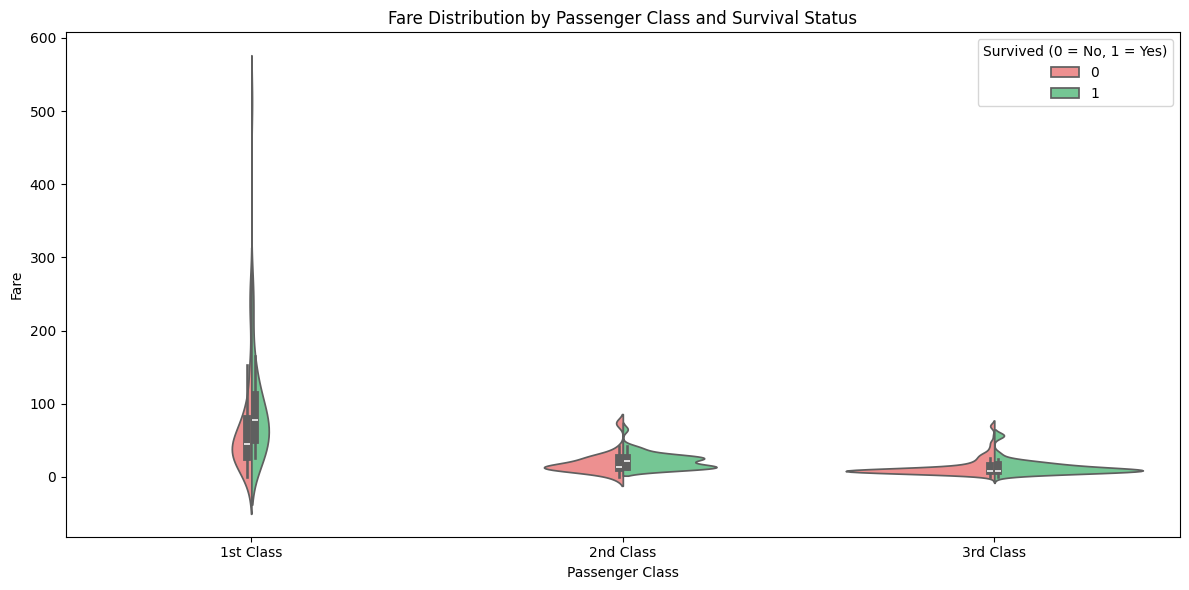

EDA tasks completed.


In [18]:
#Task 10 - Analyze fare distribution using a violin plot
plt.figure(figsize=(12, 6))
sns.violinplot(
    data=df,
    x="PclassCategory",
    y="Fare",
    hue="Survived",
    order=["1st Class", "2nd Class", "3rd Class"],
    split=True,
    palette={0: "#fc8181", 1: "#68d391"}
)
plt.title("Fare Distribution by Passenger Class and Survival Status")
plt.xlabel("Passenger Class")
plt.ylabel("Fare")
plt.legend(title="Survived (0 = No, 1 = Yes)")
plt.tight_layout()
plt.show()
print("EDA tasks completed.")


#EDA Insights & Key Takeaways:
**Overall & Class Survival:** Overall survival in the dataset is 38.4%. Survival strongly follows socioeconomic status: 1st Class passengers had a 63.0% survival rate, compared to 47.3% in 2nd Class and 24.2% in 3rd Class (Pclass correlates negatively at about -0.34 with Survived, while Fare correlates positively at about +0.26).

**Sex & Intersectionality:**  Females survived at 74.2% compared to 18.9% for males, reflecting evacuation priorities ("women and children first"). When combined with class, 1st Class females had a 96.8% survival rate and 2nd Class females 92.1%, whereas 3rd Class males had the lowest rate at 13.5%.

**Age & Missing Data:** Age had 177 missing entries; mean imputation centers missing values near 29.7 years, creating a noticeable peak around that value in the histogram and box plots. Passengers tend to be slightly older on average in 1st Class than in 2nd or 3rd Class, and 64 passengers are over age 50.

**Fare Skewness & Extreme Groups:** Ticket fares are heavily right-skewed, with top outliers reaching 512.33 among 1st Class survivors. Large families (such as the 7-member Sage family with Family = 10 in 3rd Class) faced steep coordination and evacuation challenges, resulting in 0% survival for that group in this dataset.